# TFT v3 Evaluation
# Input:  TFT_results_v3/tft_v3_best.ckpt
#         TFT_results_v3/sensor_stats.csv
#         traffic_features_v3.parquet
# Output: TFT_results_v3/tft_v3_results.json
#         TFT_figures_v3/ (all figures)

In [1]:
import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import torch
import lightning.pytorch as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.metrics import MAE

pl.seed_everything(42, workers=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.set_float32_matmul_precision("medium")

print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ── Paths ──────────────────────────────────────────────────────────────────────
FEATURES_PATH = "/home/iai-labor/traffic_project/traffic_features_v3.parquet"
RESULTS_DIR   = "/home/iai-labor/traffic_project/TFT_results_v3"
FIGURES_DIR   = "/home/iai-labor/traffic_project/TFT_figures_v3"
CHECKPOINT    = "/home/iai-labor/traffic_project/TFT_results_v3/tft_v3_best.ckpt"
os.makedirs(FIGURES_DIR, exist_ok=True)

SUBCLASS_NAMES = {0: "URB_normal", 1: "URB_ramp", 2: "M30", 3: "C30"}

# ── Verify checkpoint ──────────────────────────────────────────────────────────
assert os.path.exists(CHECKPOINT), f"Checkpoint not found: {CHECKPOINT}"
ckpt_size_mb = os.path.getsize(CHECKPOINT) / 1e6
print(f"Checkpoint confirmed: {CHECKPOINT}")
print(f"Size: {ckpt_size_mb:.1f} MB")

# ── Load training config ───────────────────────────────────────────────────────
with open(os.path.join(RESULTS_DIR, "tft_v3_config.json")) as f:
    saved = json.load(f)

CFG = saved["config"]
print(f"\nConfig loaded from training:")
print(f"  encoder_length:    {CFG['max_encoder_length']}h")
print(f"  prediction_length: {CFG['max_prediction_length']}h")
print(f"  batch_size:        {CFG['batch_size']}")
print(f"  best_val_loss:     {saved['best_val_loss']:.4f} z-score MAE")
print(f"  epochs_run:        {saved['epochs_run']}")
print(f"  train_minutes:     {saved['train_minutes']:.1f}")

Seed set to 42


Device: cuda
GPU: NVIDIA RTX A2000 12GB
Checkpoint confirmed: /home/iai-labor/traffic_project/TFT_results_v3/tft_v3_best.ckpt
Size: 5.2 MB

Config loaded from training:
  encoder_length:    48h
  prediction_length: 6h
  batch_size:        128
  best_val_loss:     0.1356 z-score MAE
  epochs_run:        56
  train_minutes:     4721.8


In [2]:
# ── Load SENSOR_STATS saved during training ────────────────────────────────────
SENSOR_STATS = pd.read_csv(
    os.path.join(RESULTS_DIR, "sensor_stats.csv"),
    index_col="SENSOR_ID"
)
print(f"SENSOR_STATS loaded: {len(SENSOR_STATS)} sensors")
print(f"Columns: {SENSOR_STATS.columns.tolist()}")
print(f"\nμ range: {SENSOR_STATS['mu'].min():.1f} – {SENSOR_STATS['mu'].max():.1f} veh/h")
print(f"σ range: {SENSOR_STATS['sigma'].min():.1f} – {SENSOR_STATS['sigma'].max():.1f} veh/h")
print(f"\nSample (first 5):")
print(SENSOR_STATS.head().to_string())

# ── Reload data — identical pipeline to training ───────────────────────────────
con = duckdb.connect()

sampled = con.sql(f"""
    WITH ranked AS (
        SELECT SENSOR_ID, road_subclass_enc, COUNT(*) AS n_obs,
               ROW_NUMBER() OVER (
                   PARTITION BY road_subclass_enc
                   ORDER BY COUNT(*) DESC, SENSOR_ID ASC
               ) AS rn
        FROM read_parquet('{FEATURES_PATH}')
        WHERE split    = 'train'
          AND target   IS NOT NULL
          AND lag_1h   IS NOT NULL
          AND lag_168h IS NOT NULL
        GROUP BY SENSOR_ID, road_subclass_enc
        HAVING COUNT(*) > 8760
    )
    SELECT SENSOR_ID, road_subclass_enc, n_obs
    FROM ranked
    WHERE rn <= {CFG['sensors_per_class']}
    ORDER BY road_subclass_enc, SENSOR_ID
""").df()

SENSOR_IDS = sampled["SENSOR_ID"].tolist()
id_list    = ",".join(map(str, SENSOR_IDS))
print(f"\nSensors: {len(SENSOR_IDS)} "
      f"({CFG['sensors_per_class']} per sub-class)")

# ── Load data ──────────────────────────────────────────────────────────────────
print("Loading data...")
t0 = time.time()

df = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, target, road_subclass_enc, split,
           longitude, latitude, is_main_artery,
           dist_station_km, dist_stadium_km, dist_hospital_km,
           dist_university_km, dist_mall_km, dist_bus_station_km,
           near_major_poi,
           hour_sin, hour_cos, dow_sin, dow_cos,
           month_sin, month_cos,
           is_weekend, is_holiday, is_rush_hour, season,
           lag_1h, lag_2h, lag_3h, lag_24h, lag_168h,
           roll_mean_3h, roll_mean_24h
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID IN ({id_list})
      AND target IS NOT NULL
      AND lag_1h IS NOT NULL
    ORDER BY SENSOR_ID, DATETIME
""").df()

df["DATETIME"]   = pd.to_datetime(df["DATETIME"])
df               = df.sort_values(["SENSOR_ID","DATETIME"]).reset_index(drop=True)
df["sensor_str"] = df["SENSOR_ID"].astype(str)
print(f"Loaded: {len(df):,} rows in {time.time()-t0:.1f}s")

# ── Time index ─────────────────────────────────────────────────────────────────
time_origin    = df["DATETIME"].min()
df["time_idx"] = (
    (df["DATETIME"] - time_origin)
    .dt.total_seconds().div(3600).round().astype(int)
)
train_end_idx = int(
    (pd.Timestamp(CFG["train_end"]) - time_origin).total_seconds() / 3600
)
val_end_idx = int(
    (pd.Timestamp(CFG["val_end"]) - time_origin).total_seconds() / 3600
)
BUFFER = CFG["max_encoder_length"]  # 48h

print(f"time_origin:    {time_origin}")
print(f"train_end_idx:  {train_end_idx}")
print(f"val_end_idx:    {val_end_idx}")
print(f"Buffer:         {BUFFER}h")

# ── Apply normalisation — MUST use training SENSOR_STATS ──────────────────────
df["mu_i"]    = df["SENSOR_ID"].map(SENSOR_STATS["mu"])
df["sigma_i"] = df["SENSOR_ID"].map(SENSOR_STATS["sigma"])

TARGET_COLS = [
    "target","lag_1h","lag_2h","lag_3h",
    "lag_24h","lag_168h","roll_mean_3h","roll_mean_24h"
]
NORM_COLS = [
    "target_norm","lag_1h_norm","lag_2h_norm","lag_3h_norm",
    "lag_24h_norm","lag_168h_norm","roll_mean_3h_norm","roll_mean_24h_norm"
]
for raw_col, norm_col in zip(TARGET_COLS, NORM_COLS):
    df[norm_col] = (df[raw_col] - df["mu_i"]) / df["sigma_i"]

# ── Splits ─────────────────────────────────────────────────────────────────────
static_cols  = [
    "longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
lag_cols_raw = [
    "lag_1h","lag_2h","lag_3h","lag_24h","lag_168h",
    "roll_mean_3h","roll_mean_24h",
]

df_train = df[df["time_idx"] <= train_end_idx].copy()
df_val   = df[
    (df["time_idx"] > train_end_idx - BUFFER) &
    (df["time_idx"] <= val_end_idx)
].copy()
df_test  = df[df["time_idx"] > val_end_idx - BUFFER].copy()

for col in static_cols:
    if df_train[col].isna().any():
        fill_val = float(df_train[col].median())
        for d in [df_train, df_val, df_test]:
            d[col] = d[col].fillna(fill_val)

df_train = df_train.dropna(subset=lag_cols_raw).reset_index(drop=True)
df_val   = df_val.dropna(subset=lag_cols_raw).reset_index(drop=True)
df_test  = df_test.dropna(subset=lag_cols_raw).reset_index(drop=True)

print(f"\nSplit sizes:")
print(f"  Train: {len(df_train):,}")
print(f"  Val:   {len(df_val):,}")
print(f"  Test:  {len(df_test):,}")

SENSOR_STATS loaded: 200 sensors
Columns: ['mu', 'sigma', 'p999']

μ range: 28.6 – 3924.1 veh/h
σ range: 12.8 – 2451.4 veh/h

Sample (first 5):
                   mu       sigma        p999
SENSOR_ID                                    
3395       282.769491  186.557911  731.457750
3396       259.816955  138.818563  674.124250
3397       341.320686  161.375515  754.000000
3398       282.846900  210.288839  972.708250
3399       162.395411  131.098714  787.597083

Sensors: 200 (50 per sub-class)
Loading data...
Loaded: 5,981,000 rows in 4.9s
time_origin:    2023-01-01 01:00:00
train_end_idx:  21167
val_end_idx:    25559
Buffer:         48h

Split sizes:
  Train: 4,200,200
  Val:   888,000
  Test:  878,600


In [3]:
# ── Feature definitions — identical to training ────────────────────────────────
STATIC_REALS = [
    "road_subclass_enc","longitude","latitude","is_main_artery",
    "dist_station_km","dist_stadium_km","dist_hospital_km",
    "dist_university_km","dist_mall_km","dist_bus_station_km",
    "near_major_poi",
]
TIME_VARYING_KNOWN_REALS = [
    "hour_sin","hour_cos","dow_sin","dow_cos",
    "month_sin","month_cos",
    "is_weekend","is_holiday","is_rush_hour","season",
]
TIME_VARYING_UNKNOWN_REALS = [
    "lag_1h_norm","lag_2h_norm","lag_3h_norm",
    "lag_24h_norm","lag_168h_norm",
    "roll_mean_3h_norm","roll_mean_24h_norm",
    "target_norm",
]

print("Creating datasets...")
t0 = time.time()

training_dataset = TimeSeriesDataSet(
    df_train,
    time_idx  = "time_idx",
    target    = "target_norm",
    group_ids = ["sensor_str"],
    max_encoder_length    = CFG["max_encoder_length"],    # 48
    min_encoder_length    = CFG["max_encoder_length"],    # 48
    max_prediction_length = CFG["max_prediction_length"], # 6
    min_prediction_length = CFG["max_prediction_length"], # 6
    static_reals               = STATIC_REALS,
    time_varying_known_reals   = TIME_VARYING_KNOWN_REALS,
    time_varying_unknown_reals = TIME_VARYING_UNKNOWN_REALS,
    target_normalizer     = None,
    add_relative_time_idx = True,
    add_target_scales     = True,
    add_encoder_length    = True,
    allow_missing_timesteps = True,
)

test_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    df_test,
    min_prediction_idx = val_end_idx + 1,
    predict            = False,
    stop_randomization = True,
)

# Boundary assertion
assert test_dataset.min_prediction_idx >= val_end_idx + 1, \
    "CONTAMINATION: test predictions start in validation period"

test_loader = test_dataset.to_dataloader(
    train       = False,
    batch_size  = CFG["batch_size"] * 2,  # 256
    num_workers = 4,
    pin_memory  = True,
)

print(f"Created in {time.time()-t0:.1f}s")
print(f"Test windows:  {len(test_dataset):,}")
print(f"Test batches:  {len(test_loader):,}  (batch=256)")
print(f"✓ Boundary assertion passed — "
      f"test starts at time_idx={test_dataset.min_prediction_idx}")

# Verify shapes
sample_x, sample_y = test_dataset[0]
enc_shape  = sample_x["encoder_target"].shape
pred_shape = sample_y[0].shape
print(f"\nSample encoder shape:    {enc_shape}   (expected (48,))")
print(f"Sample prediction shape: {pred_shape}  (expected (6,))")
assert enc_shape[0]  == CFG["max_encoder_length"],    "Encoder length mismatch"
assert pred_shape[0] == CFG["max_prediction_length"], "Prediction length mismatch"
print("✓ Encoder=48h and prediction=6h confirmed")

Creating datasets...
Created in 8.2s
Test windows:  868,000
Test batches:  3,391  (batch=256)
✓ Boundary assertion passed — test starts at time_idx=25560

Sample encoder shape:    torch.Size([48])   (expected (48,))
Sample prediction shape: torch.Size([6])  (expected (6,))
✓ Encoder=48h and prediction=6h confirmed


In [4]:
# ── Metric functions ───────────────────────────────────────────────────────────
def compute_all_metrics(preds, actuals, naive_mae):
    preds   = np.array(preds,   dtype=float).flatten()
    actuals = np.array(actuals, dtype=float).flatten()
    errors  = preds - actuals
    abs_e   = np.abs(errors)
    mae     = float(np.mean(abs_e))
    rmse    = float(np.sqrt(np.mean(errors**2)))
    mase    = float(mae / naive_mae) if naive_mae > 1e-8 else float("nan")
    denom   = np.abs(preds) + np.abs(actuals)
    smape   = float(np.mean(
        np.where(denom > 1e-8, 2.0 * abs_e / denom, 0.0)
    ) * 100)
    ss_res  = float(np.sum(errors**2))
    ss_tot  = float(np.sum((actuals - actuals.mean())**2))
    r2      = float(1.0 - ss_res / ss_tot) if ss_tot > 1e-8 else float("nan")
    return {
        "MAE":   round(mae,   2),
        "RMSE":  round(rmse,  2),
        "MASE":  round(mase,  4),
        "SMAPE": round(smape, 2),
        "R2":    round(r2,    4),
    }

def inverse_transform(pred_norm, actual_norm, sensor_str_array):
    mu_arr    = np.array([
        SENSOR_STATS.loc[int(s), "mu"]    for s in sensor_str_array
    ], dtype=float)
    sigma_arr = np.array([
        SENSOR_STATS.loc[int(s), "sigma"] for s in sensor_str_array
    ], dtype=float)
    pred_veh   = pred_norm   * sigma_arr[:, None] + mu_arr[:, None]
    actual_veh = actual_norm * sigma_arr[:, None] + mu_arr[:, None]
    pred_veh   = np.clip(pred_veh, 0, None)
    return pred_veh.astype(float), actual_veh.astype(float)

# ── Seasonal naive baseline — exact test population ───────────────────────────
# For each test target timestamp, naive prediction = same hour last week (lag 168h)
# Computed over exactly the same timestamps as model predictions
# Denominator for MASE calculation

print("Computing seasonal naive baseline...")
t0 = time.time()

SENSOR_FULL = {
    str(sid): (
        df[df["SENSOR_ID"] == sid]
        .sort_values("time_idx")
        .set_index("time_idx")["target"]
    )
    for sid in SENSOR_IDS
}

naive_errors = []
missing      = 0
for sid in SENSOR_IDS:
    sid_str      = str(sid)
    sensor_full  = SENSOR_FULL[sid_str]
    test_targets = sensor_full[sensor_full.index > val_end_idx]
    for t_idx, actual in test_targets.items():
        lag_t = t_idx - 168
        if lag_t in sensor_full.index:
            naive_errors.append(abs(actual - float(sensor_full.loc[lag_t])))
        else:
            missing += 1

naive_mae = float(np.mean(naive_errors))
print(f"Seasonal naive MAE: {naive_mae:.2f} veh/h")
print(f"Observations used:  {len(naive_errors):,}")
print(f"Missing lags:       {missing}")
print(f"Computed in:        {time.time()-t0:.1f}s")

Computing seasonal naive baseline...
Seasonal naive MAE: 139.20 veh/h
Observations used:  869,000
Missing lags:       0
Computed in:        4.6s


In [5]:
# ── Load best checkpoint ───────────────────────────────────────────────────────
print("Loading checkpoint...")
t0 = time.time()

best_tft = TemporalFusionTransformer.load_from_checkpoint(CHECKPOINT)
best_tft.eval().to(device)

total_params = sum(p.numel() for p in best_tft.parameters())
print(f"Model loaded in {time.time()-t0:.1f}s")
print(f"Parameters: {total_params:,}")
print(f"Device: {next(best_tft.parameters()).device}")

# ── Collect test predictions ───────────────────────────────────────────────────
# Predictions in z-score space — inverse transform after collection
# Carry sensor identity and decoder timestamps for per-horizon naive MAE

print("\nCollecting test predictions...")
t0 = time.time()

preds_list      = []
actuals_list    = []
sensors_list    = []
timestamps_list = []

SENSOR_STR_ORDER = df_train["sensor_str"].unique().tolist()

with torch.no_grad():
    for batch_idx, (x_b, y_b) in enumerate(test_loader):
        x_gpu = {
            k: v.to(device) if isinstance(v, torch.Tensor) else v
            for k, v in x_b.items()
        }
        out = best_tft(x_gpu)
        preds_list.append(out.prediction.squeeze(-1).cpu())
        actuals_list.append(y_b[0].cpu())

        groups_flat = x_b["groups"].numpy().flatten()
        sensors_list.append(np.array([
            SENSOR_STR_ORDER[int(g)] for g in groups_flat
        ]))
        timestamps_list.append(x_b["decoder_time_idx"].numpy())

        if (batch_idx + 1) % 500 == 0:
            print(f"  Batch {batch_idx+1:,}/{len(test_loader):,} "
                  f"— {time.time()-t0:.1f}s elapsed")

pred_norm   = torch.cat(preds_list,   dim=0).numpy()
actual_norm = torch.cat(actuals_list, dim=0).numpy()
sensor_arr  = np.concatenate(sensors_list,    axis=0)
ts_arr      = np.concatenate(timestamps_list, axis=0)

# Verify shapes
assert pred_norm.shape   == actual_norm.shape
assert pred_norm.shape[1] == CFG["max_prediction_length"]  # 6
print(f"\nPredictions shape: {pred_norm.shape}  (windows × 6 horizons)")
print(f"Sensor array shape: {sensor_arr.shape}")
print(f"Timestamp array shape: {ts_arr.shape}")
print(f"Pred z-score range: [{pred_norm.min():.3f}, {pred_norm.max():.3f}]")
print(f"Collection time: {(time.time()-t0)/60:.1f} min")

# ── Inverse transform to veh/h ─────────────────────────────────────────────────
print("\nInverse transforming to veh/h...")
pred_veh, actual_veh = inverse_transform(pred_norm, actual_norm, sensor_arr)
print(f"Pred veh/h range:   [{pred_veh.min():.1f}, {pred_veh.max():.1f}]")
print(f"Actual veh/h range: [{actual_veh.min():.1f}, {actual_veh.max():.1f}]")

# ── Save arrays for plotting cells ────────────────────────────────────────────
np.save(os.path.join(RESULTS_DIR, "tft_v3_pred_veh.npy"),   pred_veh)
np.save(os.path.join(RESULTS_DIR, "tft_v3_actual_veh.npy"), actual_veh)
np.save(os.path.join(RESULTS_DIR, "tft_v3_sensor_arr.npy"), sensor_arr)
np.save(os.path.join(RESULTS_DIR, "tft_v3_ts_arr.npy"),     ts_arr)
print("Arrays saved.")

Loading checkpoint...
Model loaded in 0.6s
Parameters: 357,071
Device: cuda:0

  Batch 500/3,391 — 61.3s elapsed
  Batch 1,000/3,391 — 121.4s elapsed
  Batch 1,500/3,391 — 181.6s elapsed
  Batch 2,000/3,391 — 242.1s elapsed
  Batch 2,500/3,391 — 302.5s elapsed
  Batch 3,000/3,391 — 363.0s elapsed

Predictions shape: (868000, 6)  (windows × 6 horizons)
Sensor array shape: (868000,)
Timestamp array shape: (868000, 6)
Pred z-score range: [-2.042, 9.789]
Collection time: 6.8 min

Inverse transforming to veh/h...
Pred veh/h range:   [0.0, 7645.1]
Actual veh/h range: [-0.0, 7666.3]
Arrays saved.


In [6]:
# ── Per-horizon exact naive MAE helper ────────────────────────────────────────
def compute_exact_naive_mae(timestamps_col, actuals_col, sensors):
    errors = []
    for i in range(len(timestamps_col)):
        t_idx  = int(timestamps_col[i])
        sid    = sensors[i]
        lag_t  = t_idx - 168
        actual = float(actuals_col[i])
        s      = SENSOR_FULL.get(sid)
        if s is None or lag_t not in s.index:
            continue
        errors.append(abs(actual - float(s.loc[lag_t])))
    return float(np.mean(errors))

# ── Per-horizon metrics ────────────────────────────────────────────────────────
print("=" * 65)
print("TFT v3 TEST RESULTS")
print(f"  encoder=48h | prediction=6h | batch=128")
print(f"  Normalisation: per-sensor z-score (target_normalizer=None)")
print(f"  Loss: MAE on z-score | best val=0.1356 at epoch 55")
print("=" * 65)
print(f"{'Horizon':<10} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'NaiveMAE':>10}")
print("-" * 65)

horizon_metrics = {}
horizon_naive   = {}

for h in range(CFG["max_prediction_length"]):
    h_label  = f"t+{h+1}h"
    h_ts     = ts_arr[:, h]
    h_act    = actual_veh[:, h]
    h_pred   = pred_veh[:, h]
    h_naive  = compute_exact_naive_mae(h_ts, h_act, sensor_arr)
    m        = compute_all_metrics(h_pred, h_act, h_naive)
    horizon_metrics[h_label] = m
    horizon_naive[h_label]   = h_naive
    status = "✓" if m["MASE"] < 1.0 else "✗"
    print(f"{h_label:<10} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {h_naive:>10.2f} {status}")

# Overall = arithmetic mean across 6 horizons
overall = {
    metric: round(float(np.mean([
        horizon_metrics[f"t+{h+1}h"][metric]
        for h in range(CFG["max_prediction_length"])
    ])), 4 if metric in ["MASE","R2"] else 2)
    for metric in ["MAE","RMSE","MASE","SMAPE","R2"]
}
print("-" * 65)
print(f"{'Overall':<10} {overall['MAE']:>8.2f} {overall['RMSE']:>8.2f} "
      f"{overall['MASE']:>7.4f} {overall['SMAPE']:>7.2f} "
      f"{overall['R2']:>7.4f}")
print(f"(Overall = arithmetic mean of 6 per-horizon values)")
print("=" * 65)

# ── Sub-class analysis ────────────────────────────────────────────────────────
sensor_to_class = (
    df.drop_duplicates("sensor_str")
      .set_index("sensor_str")["road_subclass_enc"]
      .astype(int).to_dict()
)
window_subclass = np.array([
    sensor_to_class.get(s, -1) for s in sensor_arr
])

print(f"\n{'='*65}")
print("TFT v3 — Per Road Sub-Class (test)")
print(f"{'='*65}")
print(f"{'Sub-class':<14} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print("-" * 65)

subclass_results = {}
for enc, name in SUBCLASS_NAMES.items():
    mask = window_subclass == enc
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    subclass_results[name] = m
    print(f"{name:<14} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print("=" * 65)

# ── Peak vs off-peak ──────────────────────────────────────────────────────────
window_dt    = pd.to_datetime([
    time_origin + pd.Timedelta(hours=int(t)) for t in ts_arr[:, 0]
])
window_hours = window_dt.hour
window_dow   = window_dt.dayofweek

morning_mask  = (window_hours >= 6)  & (window_hours <= 9)
evening_mask  = (window_hours >= 17) & (window_hours <= 20)
weekend_mask  = window_dow >= 5
offpeak_mask  = ~(morning_mask | evening_mask) & ~weekend_mask

print(f"\n{'='*65}")
print("TFT v3 — Peak vs Off-Peak (test)")
print(f"{'='*65}")
print(f"{'Period':<16} {'MAE':>8} {'RMSE':>8} "
      f"{'MASE':>7} {'SMAPE':>7} {'R²':>7} {'Windows':>10}")
print("-" * 68)

period_results = {}
for label, mask in [
    ("Morning peak",  morning_mask),
    ("Evening peak",  evening_mask),
    ("Weekend",       weekend_mask),
    ("Off-peak wkdy", offpeak_mask),
]:
    if mask.sum() == 0:
        continue
    m = compute_all_metrics(
        pred_veh[mask].flatten(),
        actual_veh[mask].flatten(),
        naive_mae
    )
    m["n_windows"] = int(mask.sum())
    period_results[label] = m
    print(f"{label:<16} {m['MAE']:>8.2f} {m['RMSE']:>8.2f} "
          f"{m['MASE']:>7.4f} {m['SMAPE']:>7.2f} "
          f"{m['R2']:>7.4f} {mask.sum():>10,}")
print("=" * 65)

# ── Save results ──────────────────────────────────────────────────────────────
results = {
    "model":           "TFT v3 — encoder=48h, prediction=6h",
    "normalisation":   "per-sensor z-score, target_normalizer=None",
    "best_val_loss":   0.1356,
    "epochs_run":      56,
    "naive_mae":       naive_mae,
    "horizon_metrics": horizon_metrics,
    "horizon_naive":   horizon_naive,
    "overall":         overall,
    "subclass":        subclass_results,
    "period":          period_results,
}
with open(os.path.join(RESULTS_DIR, "tft_v3_results.json"), "w") as f:
    json.dump(results, f, indent=2)
print(f"\nResults saved: {RESULTS_DIR}/tft_v3_results.json")

TFT v3 TEST RESULTS
  encoder=48h | prediction=6h | batch=128
  Normalisation: per-sensor z-score (target_normalizer=None)
  Loss: MAE on z-score | best val=0.1356 at epoch 55
Horizon         MAE     RMSE    MASE   SMAPE      R²   NaiveMAE
-----------------------------------------------------------------
t+1h          62.95   145.80  0.4522   25.44  0.9797     139.21 ✓
t+2h          72.12   179.44  0.5180   26.51  0.9692     139.24 ✓
t+3h          75.74   190.89  0.5439   26.98  0.9652     139.26 ✓
t+4h          77.94   196.92  0.5595   27.28  0.9630     139.29 ✓
t+5h          79.48   200.36  0.5705   27.48  0.9617     139.31 ✓
t+6h          81.10   204.55  0.5820   27.68  0.9600     139.33 ✓
-----------------------------------------------------------------
Overall       74.89   186.33  0.5377   26.89  0.9665
(Overall = arithmetic mean of 6 per-horizon values)

TFT v3 — Per Road Sub-Class (test)
Sub-class           MAE     RMSE    MASE   SMAPE      R²    Windows
-----------------------

Epochs with train loss: 55
Epochs with val loss:   55
LR column: lr-Adam


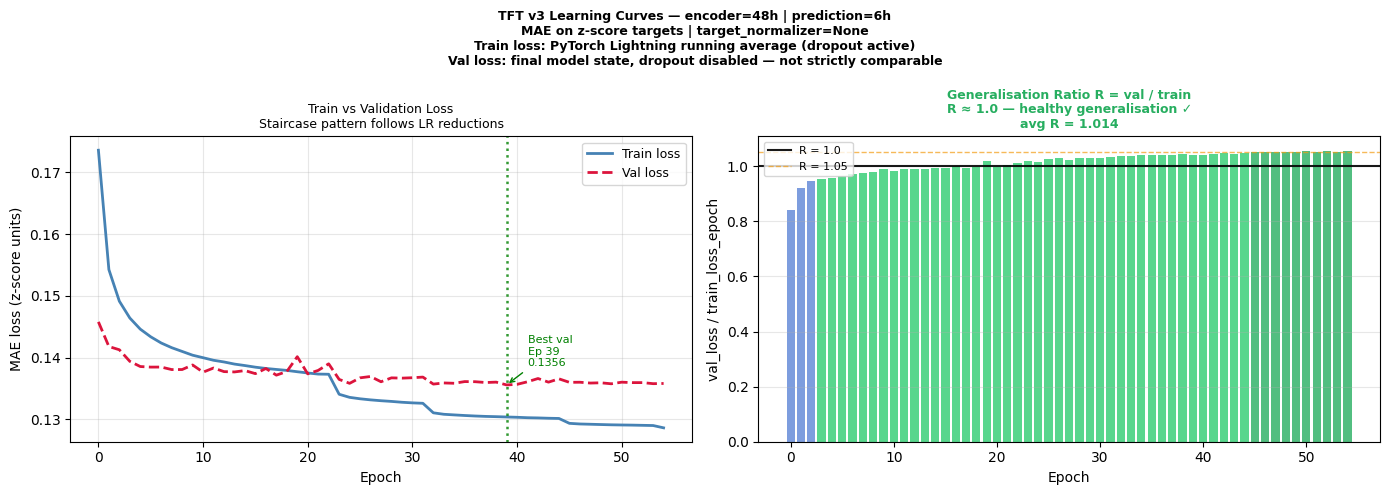

Saved: /home/iai-labor/traffic_project/TFT_figures_v3/tft_v3_loss_curves.png

Loss curve summary:
  Train: 0.1736 → 0.1286
  Val:   0.1458 → 0.1356
  Best val epoch: 39  loss=0.1356
  Avg R ratio:    1.014
  Diagnosis:      R ≈ 1.0 — healthy generalisation ✓


In [7]:
# ── Load CSV logger metrics ────────────────────────────────────────────────────
csv_path = os.path.join(
    RESULTS_DIR, "tft_training_v3", "version_0", "metrics.csv"
)
assert os.path.exists(csv_path), f"Metrics CSV not found: {csv_path}"

metrics_df = pd.read_csv(csv_path)
train_rows = metrics_df[
    metrics_df["train_loss_epoch"].notna()
].copy().reset_index(drop=True)
val_rows = metrics_df[
    metrics_df["val_loss"].notna()
].copy().reset_index(drop=True)
lr_col = next(
    (c for c in metrics_df.columns if c.lower().startswith("lr")), None
)

print(f"Epochs with train loss: {len(train_rows)}")
print(f"Epochs with val loss:   {len(val_rows)}")
print(f"LR column: {lr_col}")

# ── Figure ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "TFT v3 Learning Curves — encoder=48h | prediction=6h\n"
    "MAE on z-score targets | target_normalizer=None\n"
    "Train loss: PyTorch Lightning running average (dropout active)\n"
    "Val loss: final model state, dropout disabled — not strictly comparable",
    fontsize=9, fontweight="bold"
)

# ── Panel 1: Train vs Val loss ────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(train_rows["epoch"].values,
         train_rows["train_loss_epoch"].values,
         color="steelblue", linewidth=2.0, label="Train loss")
ax1.plot(val_rows["epoch"].values,
         val_rows["val_loss"].values,
         color="crimson", linewidth=2.0,
         linestyle="--", label="Val loss")

# Best val marker
best_epoch = int(val_rows.loc[val_rows["val_loss"].idxmin(), "epoch"])
best_loss  = float(val_rows["val_loss"].min())
ax1.axvline(x=best_epoch, color="green",
            linestyle=":", linewidth=1.8, alpha=0.8)
ax1.annotate(
    f"Best val\nEp {best_epoch}\n{best_loss:.4f}",
    xy=(best_epoch, best_loss),
    xytext=(best_epoch + 2, best_loss + 0.003),
    fontsize=8, color="green",
    arrowprops=dict(arrowstyle="->", color="green", lw=1.0)
)

# LR reduction markers
if lr_col:
    lr_rows = metrics_df[
        metrics_df[lr_col].notna() &
        metrics_df["epoch"].notna()
    ].copy()
    y_top   = float(train_rows["train_loss_epoch"].max())
    prev_lr = None
    for _, row in lr_rows.iterrows():
        if pd.isna(row["epoch"]):
            continue
        cur_lr = float(row[lr_col])
        if prev_lr is not None and cur_lr < prev_lr - 1e-10:
            ep = int(row["epoch"])
            ax1.axvline(x=ep, color="purple",
                        linestyle=":", linewidth=1.2, alpha=0.5)
            ax1.text(ep + 0.3, y_top,
                     f"LR\n{cur_lr:.0e}",
                     fontsize=6, color="purple",
                     va="top", alpha=0.8)
        prev_lr = cur_lr

ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("MAE loss (z-score units)", fontsize=10)
ax1.set_title(
    "Train vs Validation Loss\n"
    "Staircase pattern follows LR reductions",
    fontsize=9
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Panel 2: Generalisation ratio R = val / train ─────────────────────────────
ax2 = axes[1]
merged = pd.merge(
    train_rows[["epoch", "train_loss_epoch"]],
    val_rows[["epoch", "val_loss"]],
    on="epoch", how="inner"
)
ratio     = merged["val_loss"] / merged["train_loss_epoch"]
avg_ratio = float(ratio.mean())

bar_colors = [
    "#5c85d6" if r < 0.95 else
    "#2ecc71" if r < 1.05 else
    "#27ae60" if r < 1.50 else
    "#f39c12"
    for r in ratio
]
ax2.bar(merged["epoch"].values, ratio.values,
        color=bar_colors, alpha=0.80)
ax2.axhline(y=1.0, color="black",
            linewidth=1.5, alpha=0.9, label="R = 1.0")
ax2.axhline(y=1.05, color="#f39c12",
            linewidth=1.0, linestyle="--",
            alpha=0.7, label="R = 1.05")

val_vals = val_rows["val_loss"].values
if len(val_vals) >= 10:
    slope  = float(np.polyfit(
        np.arange(len(val_vals[-10:])),
        val_vals[-10:], 1
    )[0])
    rising = slope > 1e-4
else:
    rising = False

if rising:
    diagnosis, col = "Val loss rising — overfitting", "#e74c3c"
elif avg_ratio < 0.95:
    diagnosis, col = "Val < Train — data difficulty difference", "#5c85d6"
elif avg_ratio < 1.05:
    diagnosis, col = "R ≈ 1.0 — healthy generalisation ✓", "#27ae60"
else:
    diagnosis, col = "Val > Train — dropout effect (expected)", "#27ae60"

ax2.set_title(
    f"Generalisation Ratio R = val / train\n"
    f"{diagnosis}\n"
    f"avg R = {avg_ratio:.3f}",
    fontsize=9, color=col, fontweight="bold"
)
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("val_loss / train_loss_epoch", fontsize=10)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_loss_curves.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

print(f"\nLoss curve summary:")
print(f"  Train: {train_rows['train_loss_epoch'].iloc[0]:.4f} → "
      f"{train_rows['train_loss_epoch'].iloc[-1]:.4f}")
print(f"  Val:   {val_rows['val_loss'].iloc[0]:.4f} → "
      f"{val_rows['val_loss'].min():.4f}")
print(f"  Best val epoch: {best_epoch}  loss={best_loss:.4f}")
print(f"  Avg R ratio:    {avg_ratio:.3f}")
print(f"  Diagnosis:      {diagnosis}")

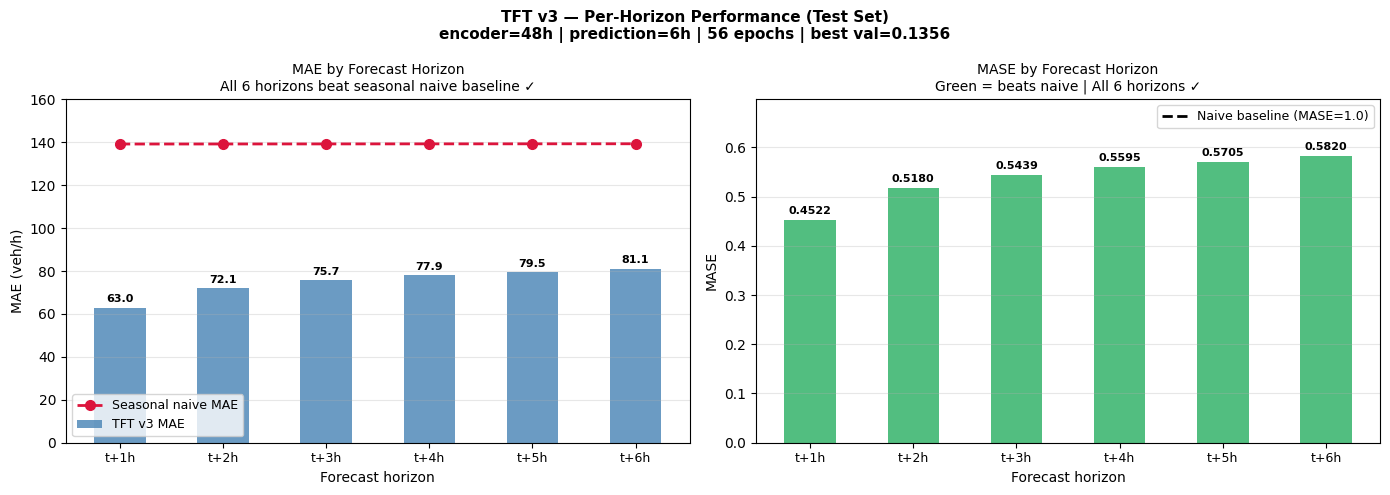

Saved: /home/iai-labor/traffic_project/TFT_figures_v3/tft_v3_horizon_metrics.png

Horizon       MAE     MASE     vs naive
----------------------------------------
t+1h        62.95   0.4522     54.8% better
t+2h        72.12   0.5180     48.2% better
t+3h        75.74   0.5439     45.6% better
t+4h        77.94   0.5595     44.0% better
t+5h        79.48   0.5705     43.0% better
t+6h        81.10   0.5820     41.8% better
Overall     74.89   0.5377


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "TFT v3 — Per-Horizon Performance (Test Set)\n"
    "encoder=48h | prediction=6h | 56 epochs | best val=0.1356",
    fontsize=11, fontweight="bold"
)

horizons   = [f"t+{h+1}h" for h in range(CFG["max_prediction_length"])]
maes       = [horizon_metrics[h]["MAE"]  for h in horizons]
mases      = [horizon_metrics[h]["MASE"] for h in horizons]
naive_maes = [horizon_naive[h]           for h in horizons]
x          = np.arange(len(horizons))

# ── Panel 1: MAE vs Naive MAE ─────────────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(x, maes, color="steelblue",
               alpha=0.8, width=0.5, label="TFT v3 MAE")
ax1.plot(x, naive_maes, color="crimson", linewidth=2.0,
         marker="o", markersize=7, linestyle="--",
         label="Seasonal naive MAE")

for bar, mae in zip(bars, maes):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f"{mae:.1f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(horizons, fontsize=9)
ax1.set_xlabel("Forecast horizon", fontsize=10)
ax1.set_ylabel("MAE (veh/h)", fontsize=10)
ax1.set_title(
    "MAE by Forecast Horizon\n"
    "All 6 horizons beat seasonal naive baseline ✓",
    fontsize=10
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3, axis="y")
ax1.set_ylim(0, max(max(maes), max(naive_maes)) * 1.15)

# ── Panel 2: MASE ─────────────────────────────────────────────────────────────
ax2 = axes[1]
bar_colors = ["#27ae60" if m < 1.0 else "#e74c3c" for m in mases]
bars2 = ax2.bar(x, mases, color=bar_colors, alpha=0.8, width=0.5)
ax2.axhline(y=1.0, color="black", linewidth=2.0,
            linestyle="--", label="Naive baseline (MASE=1.0)")

for bar, mase in zip(bars2, mases):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.008,
             f"{mase:.4f}", ha="center", va="bottom",
             fontsize=8, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels(horizons, fontsize=9)
ax2.set_xlabel("Forecast horizon", fontsize=10)
ax2.set_ylabel("MASE", fontsize=10)
ax2.set_title(
    "MASE by Forecast Horizon\n"
    "Green = beats naive | All 6 horizons ✓",
    fontsize=10
)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_ylim(0, max(mases) * 1.20)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_horizon_metrics.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

print()
print(f"{'Horizon':<8} {'MAE':>8} {'MASE':>8} {'vs naive':>12}")
print(f"{'-'*40}")
for h in horizons:
    m           = horizon_metrics[h]
    improvement = (1 - m["MASE"]) * 100
    print(f"{h:<8} {m['MAE']:>8.2f} {m['MASE']:>8.4f} "
          f"  {improvement:>6.1f}% better")
print(f"{'Overall':<8} {overall['MAE']:>8.2f} {overall['MASE']:>8.4f}")

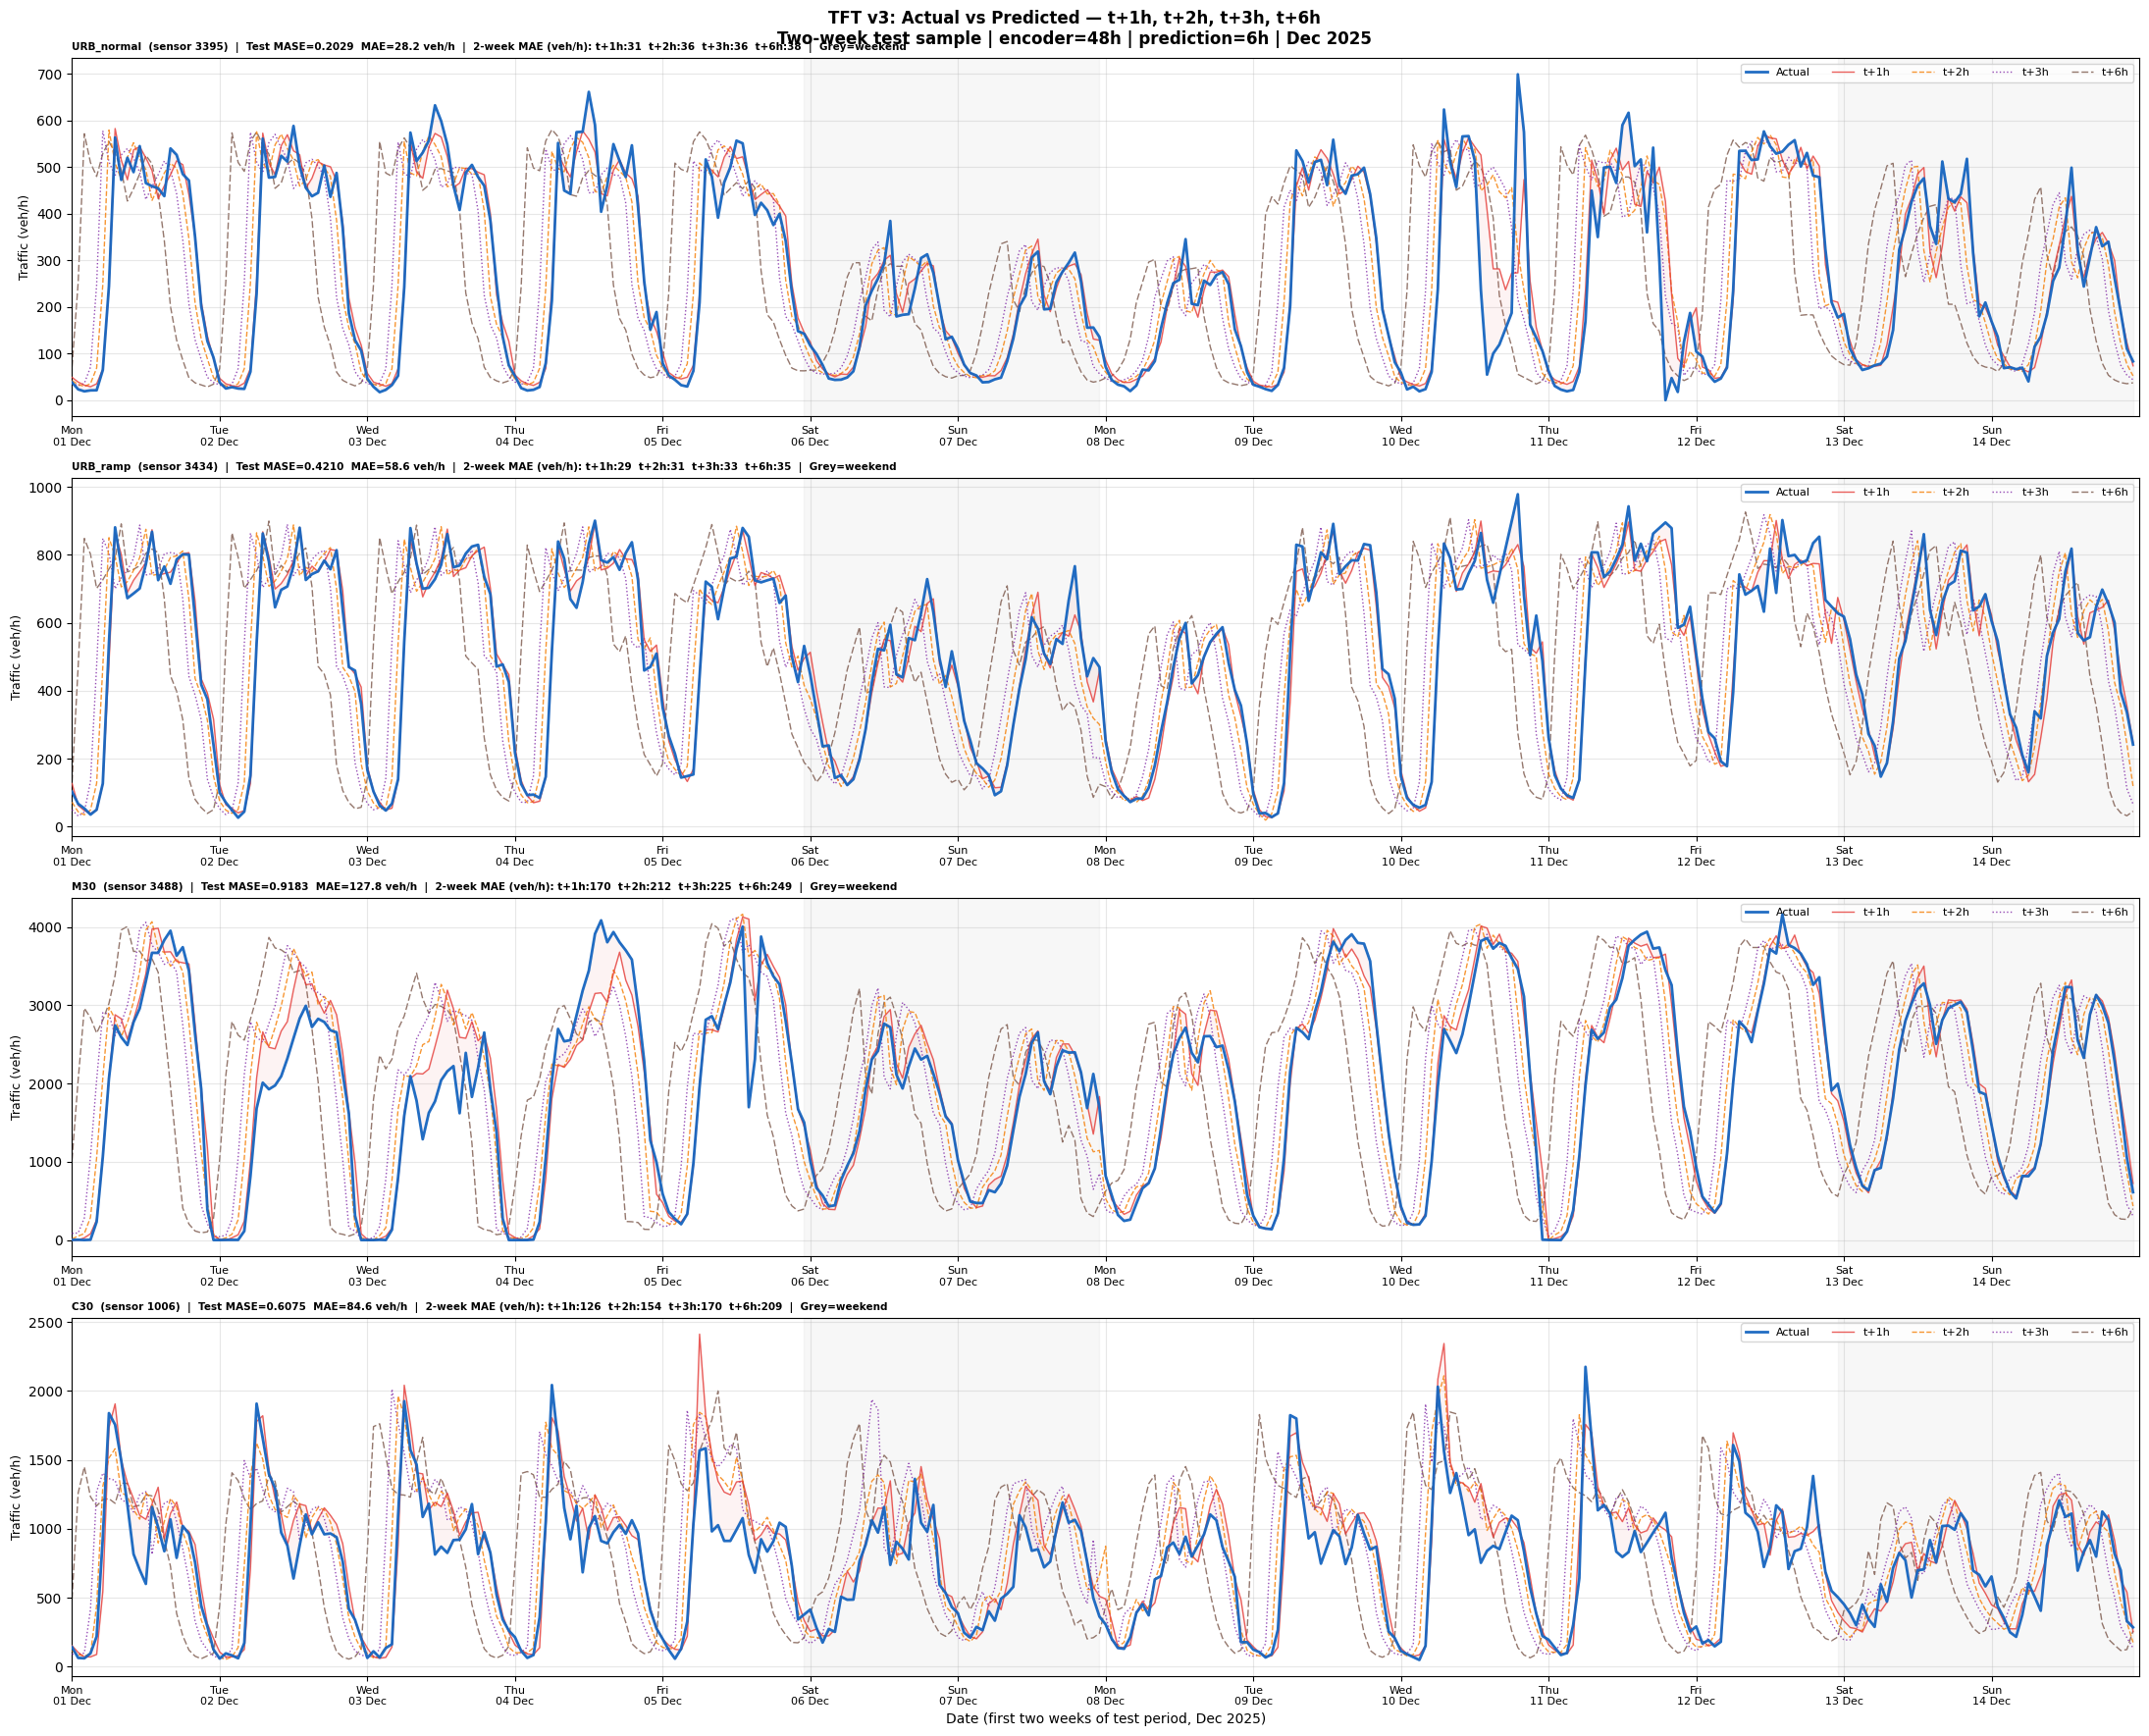

Saved: /home/iai-labor/traffic_project/TFT_figures_v3/tft_v3_twoweek_4horizons.png


In [9]:
PLOT_SENSORS = {
    "URB_normal": 3395,
    "URB_ramp":   3434,
    "M30":        3488,
    "C30":        1006,
}
TWO_WEEKS = 24 * 14

SELECTED_HORIZONS = {
    "t+1h": (0, "#E53935", "-"),
    "t+2h": (1, "#F57C00", "--"),
    "t+3h": (2, "#7B1FA2", ":"),
    "t+6h": (5, "#795548", (0, (5, 2))),
}

fig, axes = plt.subplots(4, 1, figsize=(22, 18), sharex=False)
fig.suptitle(
    "TFT v3: Actual vs Predicted — t+1h, t+2h, t+3h, t+6h\n"
    "Two-week test sample | encoder=48h | prediction=6h | Dec 2025",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    n_show   = min(TWO_WEEKS, len(sensor_indices))
    plot_idx = sensor_indices[:n_show]

    actuals_t1 = actual_veh[plot_idx, 0]
    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i, 0]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    # Actual
    ax.plot(x, actuals_t1,
            color="#1565C0", linewidth=2.0,
            alpha=0.95, label="Actual", zorder=7)

    # Selected horizons
    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.0,
                linestyle=style, alpha=0.80,
                label=h_label, zorder=6 - h_idx)

    # Error fill t+1h
    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.06, color="#E53935", zorder=2)

    # Weekend shading
    dow_vals = pd.Series(window_dts).dt.dayofweek
    i = 0
    while i < len(window_dts_list):
        if dow_vals.iloc[i] == 5:
            j = i
            while j < len(window_dts_list) and \
                    dow_vals.iloc[j] in [5, 6]:
                j += 1
            ax.axvspan(i, j, alpha=0.06, color="gray", zorder=0)
            i = j
        else:
            i += 1

    # 2-week MAE per horizon
    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx, h_idx] - actual_veh[plot_idx, h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)
    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)

    day_ticks  = list(range(0, n_show, 24))
    day_labels = [
        window_dts_list[t].strftime("%a\n%d %b")
        for t in day_ticks if t < n_show
    ]
    ax.set_xticks(day_ticks[:len(day_labels)])
    ax.set_xticklabels(day_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  MAE={mae_sc:.1f} veh/h  |  "
        f"2-week MAE (veh/h): {mae_str}  |  Grey=weekend",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Date (first two weeks of test period, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_twoweek_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

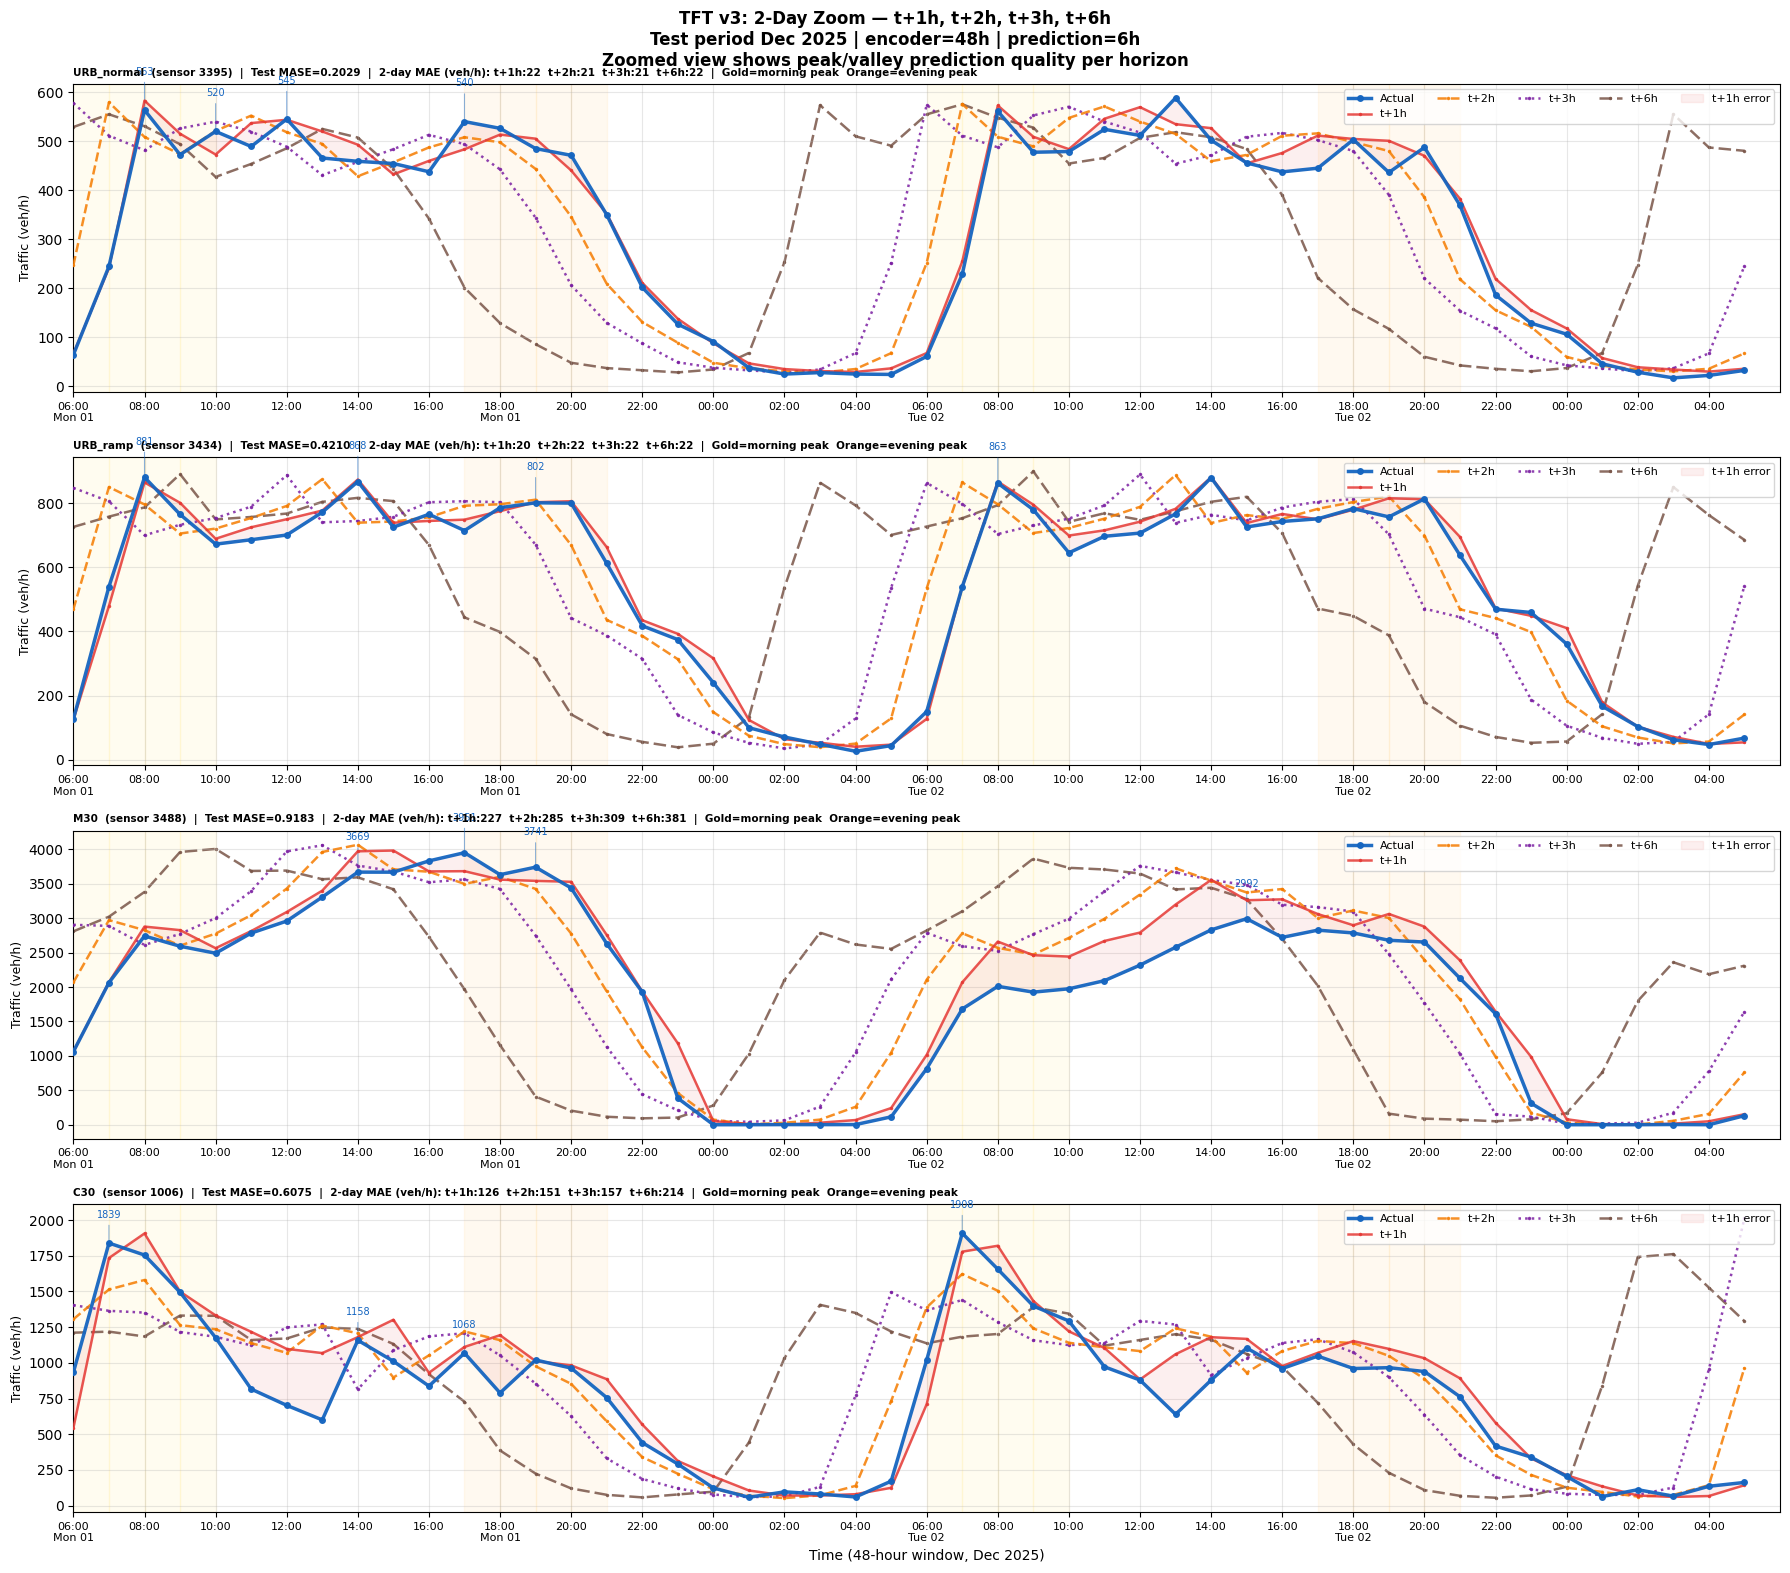

Saved: /home/iai-labor/traffic_project/TFT_figures_v3/tft_v3_twoday_4horizons.png


In [10]:
TWO_DAYS = 24 * 2

fig, axes = plt.subplots(4, 1, figsize=(18, 16), sharex=False)
fig.suptitle(
    "TFT v3: 2-Day Zoom — t+1h, t+2h, t+3h, t+6h\n"
    "Test period Dec 2025 | encoder=48h | prediction=6h\n"
    "Zoomed view shows peak/valley prediction quality per horizon",
    fontsize=12, fontweight="bold"
)

for ax, (label, sensor_id) in zip(axes, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor {sensor_id} not found")
        continue

    # Find Monday 06:00 start for clean weekday window
    start_idx = None
    for idx in sensor_indices:
        t0_hours = int(ts_arr[idx, 0])
        dt       = time_origin + pd.Timedelta(hours=t0_hours)
        if dt.dayofweek == 0 and dt.hour == 6:
            start_idx = idx
            break
    if start_idx is None:
        start_idx = sensor_indices[0]

    start_pos = np.where(sensor_indices == start_idx)[0][0]
    n_show    = min(TWO_DAYS, len(sensor_indices) - start_pos)
    plot_idx  = sensor_indices[start_pos: start_pos + n_show]

    actuals_t1 = actual_veh[plot_idx, 0]
    window_dts = pd.to_datetime([
        time_origin + pd.Timedelta(hours=int(ts_arr[i, 0]))
        for i in plot_idx
    ])
    window_dts_list = list(window_dts)
    x = np.arange(n_show)

    # Actual
    ax.plot(x, actuals_t1,
            color="#1565C0", linewidth=2.5,
            alpha=0.95, label="Actual",
            zorder=7, marker="o", markersize=4)

    # Selected horizons
    for h_label, (h_idx, color, style) in SELECTED_HORIZONS.items():
        ax.plot(x, pred_veh[plot_idx, h_idx],
                color=color, linewidth=1.8,
                linestyle=style, alpha=0.85,
                label=h_label, zorder=6 - h_idx,
                marker=".", markersize=3)

    # Error fill t+1h
    ax.fill_between(x, actuals_t1, pred_veh[plot_idx, 0],
                    alpha=0.08, color="#E53935",
                    zorder=2, label="t+1h error")

    # Morning and evening peak shading
    for i, dt in enumerate(window_dts_list):
        if 6 <= dt.hour <= 9:
            ax.axvspan(i, i + 1, alpha=0.06, color="gold",   zorder=0)
        elif 17 <= dt.hour <= 20:
            ax.axvspan(i, i + 1, alpha=0.06, color="orange", zorder=0)

    # Hour labels every 2 hours
    hour_ticks  = list(range(0, n_show, 2))
    hour_labels = [
        window_dts_list[t].strftime("%H:%M\n%a %d")
        if t % 12 == 0
        else window_dts_list[t].strftime("%H:%M")
        for t in hour_ticks if t < n_show
    ]
    ax.set_xticks(hour_ticks[:len(hour_labels)])
    ax.set_xticklabels(hour_labels, fontsize=8)
    ax.set_xlim(0, n_show)

    # Annotate peaks
    peak_threshold = np.percentile(actuals_t1, 75)
    peak_signal    = np.concatenate(
        [[actuals_t1[0]], actuals_t1, [actuals_t1[-1]]]
    )
    peaks = np.where(
        (actuals_t1 > peak_threshold) &
        (np.diff(np.sign(np.diff(peak_signal))) < 0)
    )[0]
    for pk in peaks[:4]:
        ax.annotate(
            f"{actuals_t1[pk]:.0f}",
            xy=(pk, actuals_t1[pk]),
            xytext=(pk, actuals_t1[pk] + actuals_t1.std() * 0.35),
            fontsize=7, color="#1565C0", ha="center",
            arrowprops=dict(arrowstyle="-", color="#1565C0",
                            lw=0.8, alpha=0.5)
        )

    # 2-day MAEs per horizon
    mae_str = "  ".join([
        f"{h_label}:{np.mean(np.abs(pred_veh[plot_idx, h_idx] - actual_veh[plot_idx, h_idx])):.0f}"
        for h_label, (h_idx, _, _) in SELECTED_HORIZONS.items()
    ])
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})  |  "
        f"Test MASE={mase_sc:.4f}  |  "
        f"2-day MAE (veh/h): {mae_str}  |  "
        f"Gold=morning peak  Orange=evening peak",
        fontsize=7.5, fontweight="bold", loc="left"
    )
    ax.set_ylabel("Traffic (veh/h)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8, ncol=5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Time (48-hour window, Dec 2025)", fontsize=10
)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_twoday_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

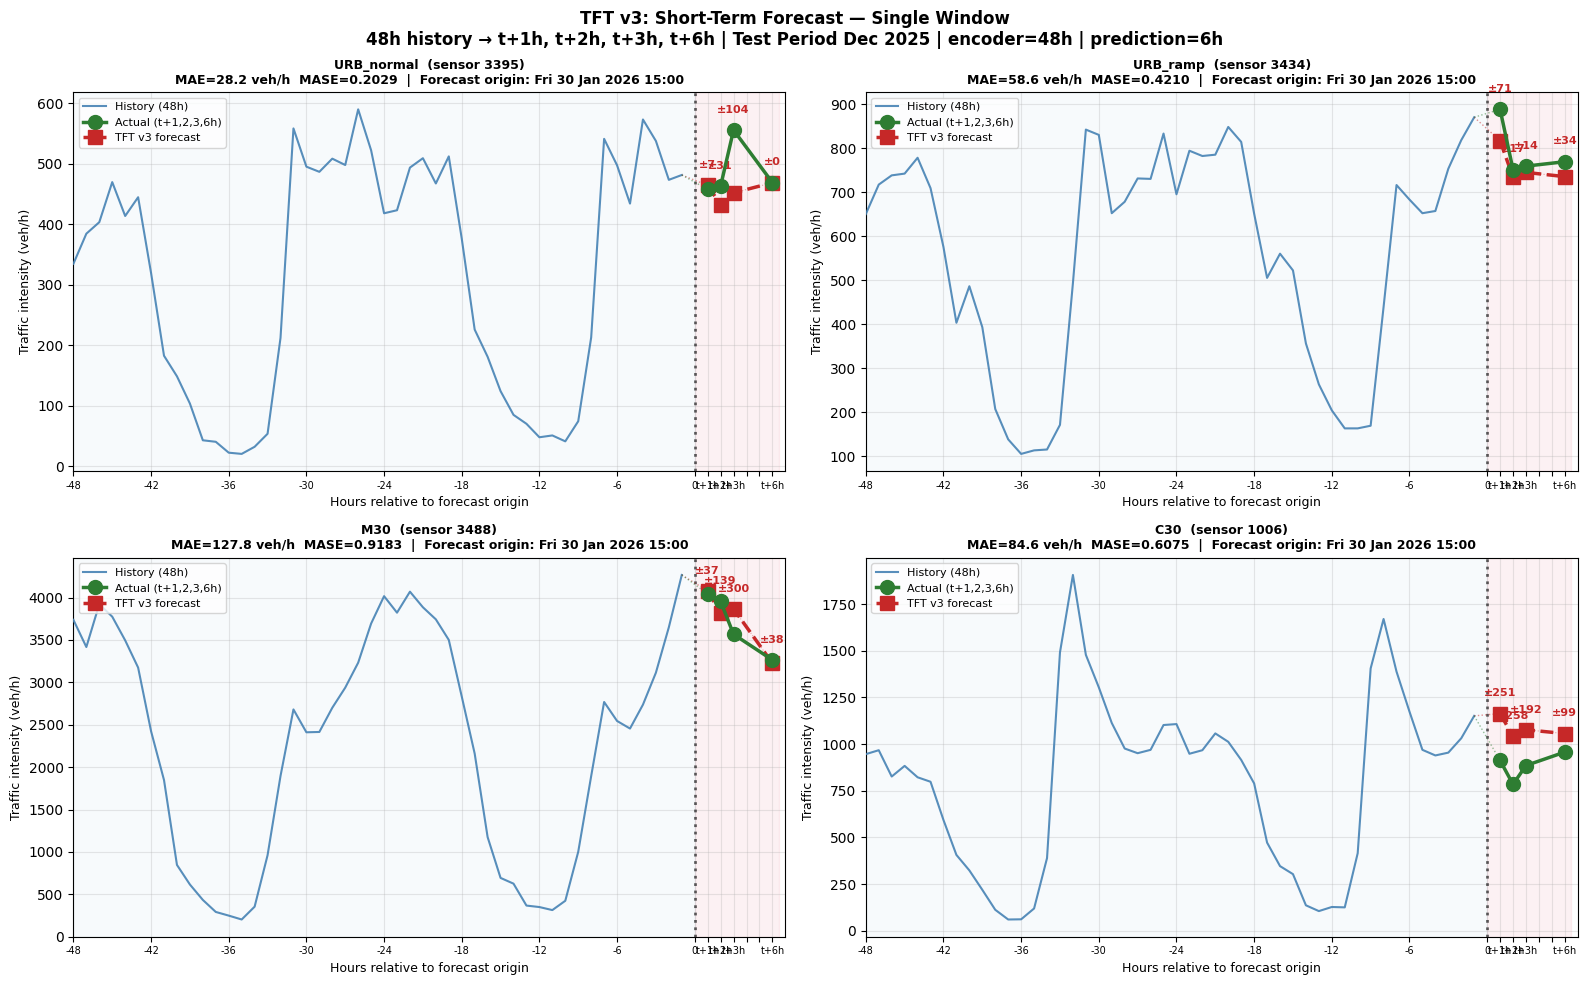

Saved: /home/iai-labor/traffic_project/TFT_figures_v3/tft_v3_snapshot_4horizons.png

All TFT v3 evaluation figures saved:
  ✓  tft_v3_loss_curves.png
  ✓  tft_v3_horizon_metrics.png
  ✓  tft_v3_twoweek_4horizons.png
  ✓  tft_v3_twoday_4horizons.png
  ✓  tft_v3_snapshot_4horizons.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "TFT v3: Short-Term Forecast — Single Window\n"
    "48h history → t+1h, t+2h, t+3h, t+6h | "
    "Test Period Dec 2025 | encoder=48h | prediction=6h",
    fontsize=12, fontweight="bold"
)

SELECTED_SNAP = {
    "t+1h": (0, "#E53935", "-"),
    "t+2h": (1, "#F57C00", "--"),
    "t+3h": (2, "#7B1FA2", ":"),
    "t+6h": (5, "#795548", (0, (5, 2))),
}

for ax, (label, sensor_id) in zip(axes.flat, PLOT_SENSORS.items()):
    sid_str        = str(sensor_id)
    sensor_mask    = sensor_arr == sid_str
    sensor_indices = np.where(sensor_mask)[0]

    if len(sensor_indices) == 0:
        ax.set_title(f"{label} — sensor not found")
        continue

    # Find weekday afternoon window with meaningful traffic
    chosen_idx = None
    search_start = len(sensor_indices) // 3
    for idx in sensor_indices[search_start: search_start + 500]:
        t_pred = int(ts_arr[idx, 0])
        dt     = time_origin + pd.Timedelta(hours=t_pred)
        if (dt.dayofweek < 5 and
                14 <= dt.hour <= 18 and
                actual_veh[idx].mean() > 100):
            chosen_idx = idx
            break
    if chosen_idx is None:
        chosen_idx = sensor_indices[len(sensor_indices) // 2]

    pred_vals   = pred_veh[chosen_idx]    # (6,)
    actual_vals = actual_veh[chosen_idx]  # (6,)

    # 48h encoder history from df
    t_start   = int(ts_arr[chosen_idx, 0]) - CFG["max_encoder_length"]
    t_end     = int(ts_arr[chosen_idx, 0]) - 1
    sensor_df = df[
        (df["SENSOR_ID"] == sensor_id) &
        (df["time_idx"].between(t_start, t_end))
    ].sort_values("time_idx")
    history = sensor_df["target"].values

    if len(history) < CFG["max_encoder_length"]:
        history = np.pad(
            history,
            (CFG["max_encoder_length"] - len(history), 0),
            constant_values=0
        )

    history_x = np.arange(-CFG["max_encoder_length"], 0)  # -48..−1
    snap_h_indices = [0, 1, 2, 5]   # t+1h, t+2h, t+3h, t+6h
    future_x       = np.array([1, 2, 3, 6])

    # History line
    ax.plot(history_x, history,
            color="steelblue", linewidth=1.5,
            alpha=0.9, label="History (48h)", zorder=3)

    # Actual future points
    actual_plot = actual_vals[snap_h_indices]
    pred_plot   = pred_vals[snap_h_indices]

    ax.plot(future_x, actual_plot,
            color="#2E7D32", linewidth=2.5,
            marker="o", markersize=10,
            label="Actual (t+1,2,3,6h)", zorder=5)
    ax.plot(future_x, pred_plot,
            color="#C62828", linewidth=2.5,
            marker="s", markersize=10,
            linestyle="--",
            label="TFT v3 forecast", zorder=4)

    # Dotted bridge t+3 → t+6 (skipped t+4, t+5)
    ax.plot([3, 6], [actual_vals[2], actual_vals[5]],
            color="#2E7D32", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)
    ax.plot([3, 6], [pred_vals[2], pred_vals[5]],
            color="#C62828", linewidth=0.8,
            linestyle=":", alpha=0.4, zorder=3)

    # Connect history to first forecast point
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], pred_plot[0]],
            color="#C62828", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)
    ax.plot([history_x[-1], future_x[0]],
            [history[-1], actual_plot[0]],
            color="#2E7D32", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)

    # Forecast origin line
    ax.axvline(x=0, color="black", linestyle=":",
               linewidth=2.0, alpha=0.6)

    # Shading regions
    ax.axvspan(-CFG["max_encoder_length"], 0,
               alpha=0.04, color="steelblue")
    ax.axvspan(0, 6.5, alpha=0.06, color="crimson")

    # Error annotations
    y_range = (
        max(history.max(), actual_plot.max(), pred_plot.max()) -
        min(history.min(), actual_plot.min(), pred_plot.min())
    )
    for i, fx in enumerate(future_x):
        err  = abs(pred_plot[i] - actual_plot[i])
        ypos = max(pred_plot[i], actual_plot[i]) + y_range * 0.05
        ax.annotate(
            f"±{err:.0f}",
            xy=(fx, ypos),
            fontsize=8, color="#C62828",
            ha="center", fontweight="bold"
        )

    # X ticks — every 6h for 48h history
    xtick_hist   = list(range(-48, 0, 6))
    xtick_labels = (
        [str(h) for h in xtick_hist] +
        ["0", "t+1h", "t+2h", "t+3h", "", "", "t+6h"]
    )
    ax.set_xticks(xtick_hist + [0, 1, 2, 3, 4, 5, 6])
    ax.set_xticklabels(xtick_labels, fontsize=7)
    ax.set_xlim(-48, 7)

    forecast_dt = (
        time_origin + pd.Timedelta(hours=int(ts_arr[chosen_idx, 0]))
    ).strftime("%a %d %b %Y %H:%M")

    mae_sc  = subclass_results.get(label, {}).get("MAE",  0)
    mase_sc = subclass_results.get(label, {}).get("MASE", 0)

    ax.set_title(
        f"{label}  (sensor {sensor_id})\n"
        f"MAE={mae_sc:.1f} veh/h  MASE={mase_sc:.4f}  |  "
        f"Forecast origin: {forecast_dt}",
        fontsize=9, fontweight="bold"
    )
    ax.set_xlabel("Hours relative to forecast origin", fontsize=9)
    ax.set_ylabel("Traffic intensity (veh/h)", fontsize=9)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "tft_v3_snapshot_4horizons.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")
print()
print("All TFT v3 evaluation figures saved:")
for fname in [
    "tft_v3_loss_curves.png",
    "tft_v3_horizon_metrics.png",
    "tft_v3_twoweek_4horizons.png",
    "tft_v3_twoday_4horizons.png",
    "tft_v3_snapshot_4horizons.png",
]:
    fpath = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")